In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT / "tests"))
TABLES, FIGS, PROC = ROOT / "reports/tables", ROOT / "reports/figures", ROOT / "data/processed"
from olpred.viz import style; style.apply()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

def show(name, width=820):
    display(Image(filename=str(FIGS / name), width=width))

def table(name, **kw):
    return pd.read_csv(TABLES / name, **kw)


# 03 — Baselines (validation 2021–22)
Frequencies, league table, Elo, Poisson goals, logistic regression, and the bookmaker as reference. Report: `docs/phase4_baselines.md`.

In [2]:
table("phase4_baselines_val.csv", index_col=0).round(4)

,log_loss,brier,rps,accuracy,f1_macro,f1_draw,ece,C
model,,,,,,,,
Class frequency (naive),1.0704,0.6474,0.2298,0.4423,0.2045,0.0000,NaN,NaN
League table (LogReg),1.0155,0.6085,0.2105,0.5105,0.3710,0.0000,0.0207,0.3728
Elo (LogReg),0.9962,0.5940,0.2038,0.5248,0.3879,0.0000,0.0146,1.9307
Poisson goals,0.9964,0.5943,0.2039,0.5264,0.3892,0.0000,0.0195,NaN
LogReg: Elo + form,0.9917,0.5909,0.2025,0.5292,0.3920,0.0000,0.0177,0.0720
LogReg: all features,0.9859,0.5868,0.2009,0.5303,0.3985,0.0086,0.0190,0.0027
Bookmaker Bet365 (reference),0.9781,0.5819,0.1983,0.5338,0.3976,0.0000,0.0171,NaN


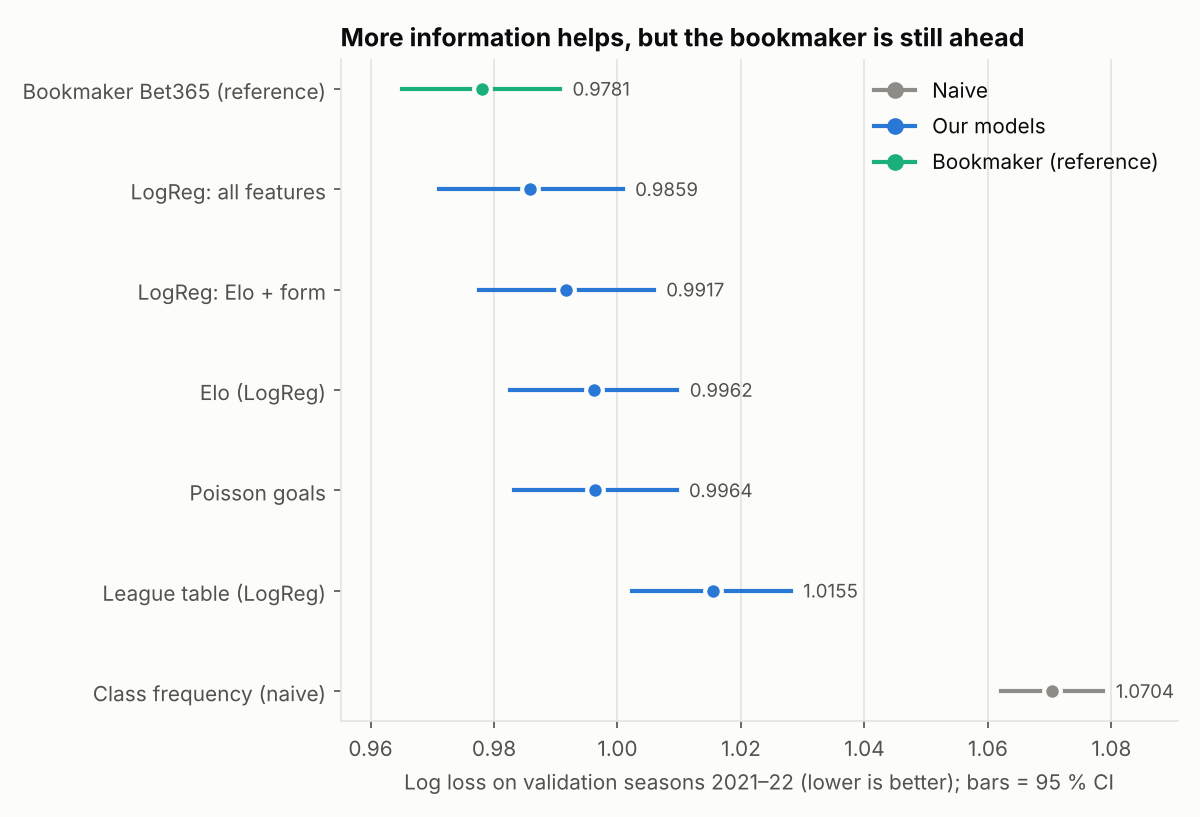

In [3]:
show("phase4_logloss.png")

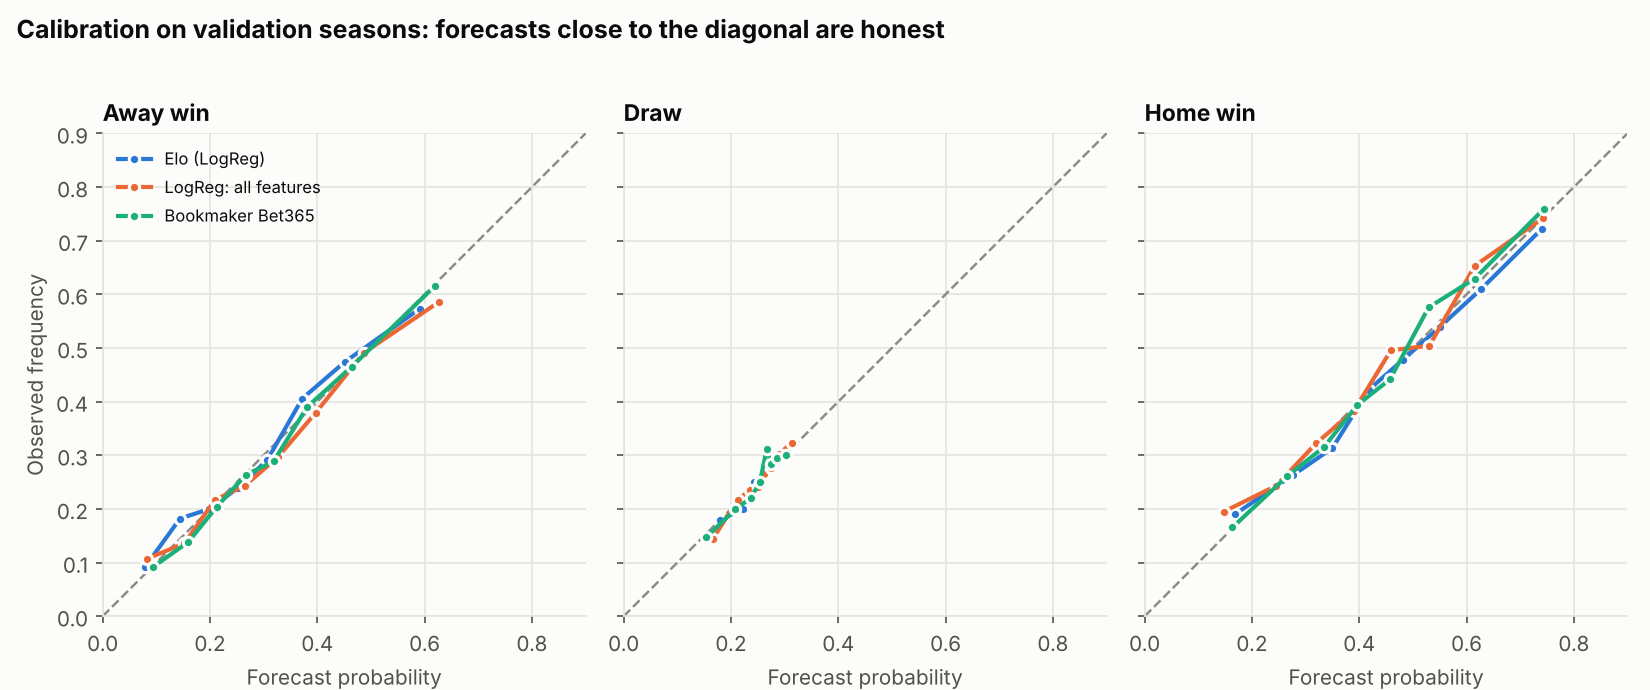

In [4]:
show("phase4_reliability.png", 980)

Paired block-bootstrap differences in log loss:

In [5]:
b = table("phase4_baselines_val_bootstrap.csv"); b[b.vs=="Elo (LogReg)"].round(4)

,model,vs,diff,ci_low,ci_high,significant
0,Class frequency (naive),Elo (LogReg),0.0742,0.0623,0.0863,True
3,League table (LogReg),Elo (LogReg),0.0193,0.0106,0.0281,True
8,Poisson goals,Elo (LogReg),0.0002,-0.0024,0.0029,False
11,LogReg: Elo + form,Elo (LogReg),-0.0045,-0.0079,-0.0011,True
14,LogReg: all features,Elo (LogReg),-0.0103,-0.0155,-0.0052,True
17,Bookmaker Bet365 (reference),Elo (LogReg),-0.0181,-0.0234,-0.0125,True


**Reading.** Team strength carries almost everything; extra features add about 0.010 log loss; the bookmaker remains ahead; draws are never the most probable outcome; calibration is good.